### Task 1: Design and Populate Database Tables

Uses SQLAlchemy to create and populate five reference tables and three summary tables in SQLite. Validates database relationships and record counts, then generates reporting summaries for yearly crimes, crime categories and arrests using SQL aggregation.

In [6]:

# ============================================================
# USE CASE 4 - CODE CELL 1
# TASK 1: DESIGN AND POPULATE DATABASE TABLES
# ============================================================

# Assessment Requirements:
# 1. Create database tables using Python.
# 2. Load the supplied reference datasets.
# 3. Design and populate summary tables for reporting.
#
# Methods Used:
# pd.read_csv() loads the reference datasets.
# SQLAlchemy create_engine() connects to SQLite3.
# Table() and Column() define database schemas.
# metadata.create_all() creates missing tables.
# to_sql() inserts data into the database.
# SQL GROUP BY calculates reporting summaries.



# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

from pathlib import Path
import pandas as pd
from IPython.display import display

from sqlalchemy import (
    create_engine,
    MetaData,
    Table,
    Column,
    Integer,
    Float,
    String,
    Text,
    inspect,
    text
)


# ============================================================
# STEP 2: LOCATE THE NEW PROJECT AND DATABASE
# ============================================================

BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

assert BASE_DIR.name == "Chicago_Crime_Capstone_2026", (
    f"Incorrect project directory: {BASE_DIR}"
)

RAW_DIR = BASE_DIR / "data" / "raw"

DB_FILE = (
    BASE_DIR / "data" / "chicago_crime.db"
)

assert DB_FILE.is_file(), (
    "Database not found. Run Notebook 01 - Code Cell 5."
)

# Connect to the SQLite database created in Use Case 1.
engine = create_engine(
    f"sqlite:///{DB_FILE.as_posix()}",
    future=True
)

print("========== DATABASE CONNECTION ==========")
print("Database:", DB_FILE.name)


# ============================================================
# STEP 3: VERIFY THE EXISTING CRIME TABLE
# ============================================================

# The crime_records table was created in Notebook 01.
# It must contain all 498 cleaned crime records.
db_inspector = inspect(engine)

assert db_inspector.has_table("crime_records"), (
    "crime_records table not found."
)

with engine.connect() as connection:

    master_count = connection.execute(
        text("SELECT COUNT(*) FROM crime_records")
    ).scalar_one()

assert master_count == 498, (
    f"Expected 498 crime records, found {master_count}"
)

print("Existing Crime Records:", master_count)


# ============================================================
# STEP 4: LOAD THE FIVE REFERENCE DATASETS
# ============================================================

# Read all reference columns as text initially.
# This preserves values such as phone numbers, ZIP codes,
# leading zeros, and other source identifiers.

reference_files = {
    "iucr_codes": "iucr_codes.csv.csv",
    "police_districts": "chicago_district_ps_info.csv",
    "ward_offices": "chicago_ward_offices.csv",
    "community_areas": "chicago_city_community.csv",
    "police_beats": "chicago_police_beat_info.csv"
}

reference_data = {}

for table_name, filename in reference_files.items():

    file_path = RAW_DIR / filename

    # Support the normal IUCR filename if it was renamed.
    if table_name == "iucr_codes" and not file_path.is_file():
        file_path = RAW_DIR / "iucr_codes.csv"

    assert file_path.is_file(), (
        f"Missing reference file: {filename}"
    )

    ref_df = pd.read_csv(
        file_path,
        dtype=str,
        keep_default_na=False
    )

    # Standardize column headers for SQL table names.
    ref_df.columns = (
        ref_df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )

    # Remove surrounding whitespace without deleting rows.
    for column in ref_df.columns:

        ref_df[column] = (
            ref_df[column]
            .astype(str)
            .str.strip()
        )

    reference_data[table_name] = ref_df


# ============================================================
# STEP 5: PREPARE REFERENCE TABLE KEYS
# ============================================================

# Rename the IUCR key to match crime_records.iucr_code.
iucr_df = reference_data["iucr_codes"].rename(
    columns={"iucr": "iucr_code"}
)

# Standardize IUCR codes to four characters.
iucr_df["iucr_code"] = (
    iucr_df["iucr_code"].str.upper().str.zfill(4)
)

iucr_df["primary_type"] = (
    iucr_df["primary_type"].str.upper()
)

reference_data["iucr_codes"] = iucr_df


# Convert police district identifiers into integers.
district_df = reference_data["police_districts"]

district_df["district_code"] = pd.to_numeric(
    district_df["district_code"],
    errors="raise"
).astype(int)

reference_data["police_districts"] = district_df


# Convert community identifiers into integers.
community_df = reference_data["community_areas"]

community_df["community_code"] = pd.to_numeric(
    community_df["community_code"],
    errors="raise"
).astype(int)

reference_data["community_areas"] = community_df


# Some ward numbers appear more than once.
# Add a separate record ID to preserve all 58 entries.
ward_df = reference_data["ward_offices"].rename(
    columns={"ward": "ward_no"}
)

ward_df.insert(
    0,
    "ward_record_id",
    range(1, len(ward_df) + 1)
)

ward_df["ward_no"] = pd.to_numeric(
    ward_df["ward_no"],
    errors="raise"
).astype(int)

reference_data["ward_offices"] = ward_df


# Some beat numbers also appear more than once.
# Add a separate record ID to retain all 277 entries.
beat_df = reference_data["police_beats"]

beat_df.insert(
    0,
    "beat_record_id",
    range(1, len(beat_df) + 1)
)

for column in ["district", "sector", "beat", "beat_num"]:

    beat_df[column] = pd.to_numeric(
        beat_df[column],
        errors="raise"
    ).astype(int)

reference_data["police_beats"] = beat_df


# ============================================================
# STEP 6: VALIDATE REFERENCE DATASETS
# ============================================================

expected_reference_counts = {
    "iucr_codes": 410,
    "police_districts": 22,
    "ward_offices": 58,
    "community_areas": 77,
    "police_beats": 277
}

# Primary key definitions for reference tables.
primary_keys = {
    "iucr_codes": "iucr_code",
    "police_districts": "district_code",
    "ward_offices": "ward_record_id",
    "community_areas": "community_code",
    "police_beats": "beat_record_id"
}

for table_name, ref_df in reference_data.items():

    assert len(ref_df) == expected_reference_counts[table_name]

    key_column = primary_keys[table_name]

    assert ref_df[key_column].is_unique, (
        f"Duplicate primary keys found in {table_name}"
    )

print("\n========== REFERENCE DATASETS VALIDATED ==========")

for table_name, ref_df in reference_data.items():

    print(f"{table_name}: {len(ref_df)} records")


# ============================================================
# STEP 7: DESIGN THE DATABASE TABLE SCHEMAS
# ============================================================

# MetaData stores SQLAlchemy table definitions.
metadata = MetaData()

# Integer fields are stored using SQLite INTEGER.
# Other original reference values remain TEXT.
integer_fields = {
    "district_code",
    "community_code",
    "ward_record_id",
    "ward_no",
    "beat_record_id",
    "district",
    "sector",
    "beat",
    "beat_num"
}

# Dynamically define all reference columns.
# This preserves every field in the supplied CSV files.
for table_name, ref_df in reference_data.items():

    key_column = primary_keys[table_name]

    table_columns = []

    for column_name in ref_df.columns:

        if column_name == "iucr_code":

            column_type = String(10)

        elif column_name in integer_fields:

            column_type = Integer

        else:

            column_type = Text

        table_columns.append(
            Column(
                column_name,
                column_type,
                primary_key=(column_name == key_column)
            )
        )

    Table(
        table_name,
        metadata,
        *table_columns
    )


# ============================================================
# STEP 8: DESIGN THE THREE SUMMARY TABLES
# ============================================================

# Summary 1: Crime counts grouped by year.
Table(
    "summary_crime_yearly",
    metadata,

    Column("year", Integer, primary_key=True),
    Column("crime_count", Integer, nullable=False)
)

# Summary 2: Crime categories, counts and percentages.
Table(
    "summary_crime_by_category",
    metadata,

    Column("primary_type", String(100), primary_key=True),
    Column("crime_count", Integer, nullable=False),
    Column("percentage", Float, nullable=False)
)

# Summary 3: Arrest counts and percentages by year.
Table(
    "summary_arrests_yearly",
    metadata,

    Column("year", Integer, primary_key=True),
    Column("total_crimes", Integer, nullable=False),
    Column("arrest_count", Integer, nullable=False),
    Column("arrest_percentage", Float, nullable=False)
)

# Create only tables that do not already exist.
# Existing crime and reference records remain untouched.
metadata.create_all(engine)


# ============================================================
# STEP 9: INSERT REFERENCE DATA INTO SQLITE
# ============================================================

# Use a transaction to safely insert reference records.
with engine.begin() as connection:

    for table_name, ref_df in reference_data.items():

        existing_count = connection.execute(
            text(f'SELECT COUNT(*) FROM "{table_name}"')
        ).scalar_one()

        if existing_count == 0:

            # Insert all reference records into the
            # SQLAlchemy-created table.
            ref_df.to_sql(
                name=table_name,
                con=connection,
                if_exists="append",
                index=False
            )

        else:

            # Prevent duplicate insertion on reruns.
            assert existing_count == len(ref_df), (
                f"Unexpected existing rows in {table_name}"
            )

            # Check that the stored primary keys match
            # the current reference dataset.
            key_column = primary_keys[table_name]

            stored_keys = pd.read_sql_query(
                text(
                    f'SELECT "{key_column}" '
                    f'FROM "{table_name}"'
                ),
                connection
            )[key_column]

            assert set(stored_keys.astype(str)) == set(
                ref_df[key_column].astype(str)
            ), (
                f"Stored keys differ in {table_name}"
            )


# ============================================================
# STEP 10: VALIDATE CRIME-REFERENCE RELATIONSHIPS
# ============================================================

# Check that the crime identifiers match their reference
# tables before building analytical summaries.
#
# The existing crime table remains unchanged.
# These joins validate the logical table relationships.

with engine.connect() as connection:

    missing_iucr = connection.execute(
        text("""
            SELECT COUNT(*)
            FROM crime_records AS c
            LEFT JOIN iucr_codes AS i
                ON c.iucr_code = i.iucr_code
            WHERE i.iucr_code IS NULL
        """)
    ).scalar_one()

    missing_districts = connection.execute(
        text("""
            SELECT COUNT(*)
            FROM crime_records AS c
            LEFT JOIN police_districts AS d
                ON c.district_code = d.district_code
            WHERE d.district_code IS NULL
        """)
    ).scalar_one()

    missing_communities = connection.execute(
        text("""
            SELECT COUNT(*)
            FROM crime_records AS c
            LEFT JOIN community_areas AS a
                ON c.community_code = a.community_code
            WHERE a.community_code IS NULL
        """)
    ).scalar_one()

assert missing_iucr == 0
assert missing_districts == 0
assert missing_communities == 0

print("\n========== REFERENCE MATCH VALIDATION ==========")

print("Unmatched IUCR Codes:", missing_iucr)
print("Unmatched District Codes:", missing_districts)
print("Unmatched Community Codes:", missing_communities)


# ============================================================
# STEP 11: POPULATE THE SUMMARY TABLES
# ============================================================

# Use SQL GROUP BY to create analytical summaries.
# Refresh only the derived summary tables on reruns.
# The original crime and reference tables are preserved.

with engine.begin() as connection:

    # Summary 1: Crime count per year.
    connection.execute(
        text("DELETE FROM summary_crime_yearly")
    )

    connection.execute(
        text("""
            INSERT INTO summary_crime_yearly (
                year,
                crime_count
            )
            SELECT
                year,
                COUNT(*)
            FROM crime_records
            GROUP BY year
        """)
    )

    # Summary 2: Crime types and percentages.
    # Join crime_records with IUCR reference data.
    connection.execute(
        text("DELETE FROM summary_crime_by_category")
    )

    connection.execute(
        text("""
            INSERT INTO summary_crime_by_category (
                primary_type,
                crime_count,
                percentage
            )
            SELECT
                i.primary_type,
                COUNT(*) AS crime_count,
                ROUND(
                    COUNT(*) * 100.0 /
                    (SELECT COUNT(*) FROM crime_records),
                    2
                ) AS percentage
            FROM crime_records AS c
            JOIN iucr_codes AS i
                ON c.iucr_code = i.iucr_code
            GROUP BY i.primary_type
        """)
    )

    # Summary 3: Arrest count per year.
    # SQLite stores Boolean TRUE/FALSE as 1/0.
    connection.execute(
        text("DELETE FROM summary_arrests_yearly")
    )

    connection.execute(
        text("""
            INSERT INTO summary_arrests_yearly (
                year,
                total_crimes,
                arrest_count,
                arrest_percentage
            )
            SELECT
                year,
                COUNT(*) AS total_crimes,
                SUM(
                    CASE WHEN arrest = 1 THEN 1 ELSE 0 END
                ) AS arrest_count,
                ROUND(
                    SUM(
                        CASE WHEN arrest = 1
                        THEN 1 ELSE 0 END
                    ) * 100.0 / COUNT(*),
                    2
                ) AS arrest_percentage
            FROM crime_records
            GROUP BY year
        """)
    )


# ============================================================
# STEP 12: READ THE GENERATED SUMMARY TABLES
# ============================================================

# Pandas reads the SQL results back into DataFrames.
with engine.connect() as connection:

    yearly_summary = pd.read_sql_query(
        text("""
            SELECT *
            FROM summary_crime_yearly
            ORDER BY year
        """),
        connection
    )

    category_summary = pd.read_sql_query(
        text("""
            SELECT *
            FROM summary_crime_by_category
            ORDER BY crime_count DESC, primary_type
        """),
        connection
    )

    arrests_summary = pd.read_sql_query(
        text("""
            SELECT *
            FROM summary_arrests_yearly
            ORDER BY year
        """),
        connection
    )


# ============================================================
# STEP 13: DISPLAY THE SUMMARY RESULTS
# ============================================================

print("\n========== CRIME COUNT PER YEAR ==========")
display(yearly_summary)

print("\n========== TOP 5 CRIME TYPES ==========")
display(category_summary.head(5))

print("\n========== ARREST COUNT PER YEAR ==========")
display(arrests_summary)


# ============================================================
# STEP 14: VERIFY DATABASE RECORD COUNTS
# ============================================================

with engine.connect() as connection:

    final_counts = {}

    all_table_names = [
        "crime_records",
        *reference_data.keys(),
        "summary_crime_yearly",
        "summary_crime_by_category",
        "summary_arrests_yearly"
    ]

    for table_name in all_table_names:

        final_counts[table_name] = connection.execute(
            text(f'SELECT COUNT(*) FROM "{table_name}"')
        ).scalar_one()

# Verify master and reference counts.
assert final_counts["crime_records"] == 498

for table_name, expected_count in expected_reference_counts.items():

    assert final_counts[table_name] == expected_count

# Verify summary counts and totals.
assert yearly_summary["crime_count"].sum() == 498
assert len(yearly_summary) == 5

assert category_summary["crime_count"].sum() == 498
assert len(category_summary) == 23

assert arrests_summary["total_crimes"].sum() == 498
assert arrests_summary["arrest_count"].sum() == 124

print("\n========== DATABASE TABLE VALIDATION ==========")

table_summary = pd.DataFrame([
    {
        "table_name": table_name,
        "record_count": record_count
    }
    for table_name, record_count in final_counts.items()
])

display(table_summary)


# ============================================================
# STEP 15: FINAL COMPLETION STATUS
# ============================================================

print("\n========== USE CASE 4 - TASK 1 SUMMARY ==========")

print("Database:", DB_FILE.name)
print("Original Crime Records:", final_counts["crime_records"])
print("Reference Tables Created/Verified: 5")
print("Summary Tables Created/Populated: 3")
print("Total Database Tables:", len(final_counts))

print("\nUSE CASE 4 - TASK 1: PASS")


========== DATABASE CONNECTION ==========
Database: chicago_crime.db
Existing Crime Records: 498

========== REFERENCE DATASETS VALIDATED ==========
iucr_codes: 410 records
police_districts: 22 records
ward_offices: 58 records
community_areas: 77 records
police_beats: 277 records

========== REFERENCE MATCH VALIDATION ==========
Unmatched IUCR Codes: 0
Unmatched District Codes: 0
Unmatched Community Codes: 0

========== CRIME COUNT PER YEAR ==========


,year,crime_count
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490



========== TOP 5 CRIME TYPES ==========


,primary_type,crime_count,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63



========== ARREST COUNT PER YEAR ==========


,year,total_crimes,arrest_count,arrest_percentage
0,2012,2,2,100.00
1,2013,1,1,100.00
2,2014,1,0,0.00
3,2015,4,2,50.00
4,2016,490,119,24.29



========== DATABASE TABLE VALIDATION ==========


,table_name,record_count
0,crime_records,498
1,iucr_codes,410
2,police_districts,22
3,ward_offices,58
4,community_areas,77
5,police_beats,277
6,summary_crime_yearly,5
7,summary_crime_by_category,23
8,summary_arrests_yearly,5



========== USE CASE 4 - TASK 1 SUMMARY ==========
Database: chicago_crime.db
Original Crime Records: 498
Reference Tables Created/Verified: 5
Summary Tables Created/Populated: 3
Total Database Tables: 9

USE CASE 4 - TASK 1: PASS


### Task 2: SQL Queries for Crime Reporting

Executes SQL queries using GROUP BY, JOIN and aggregate functions to calculate yearly crime counts, the top five crime categories with percentages and yearly arrest statistics. Displays the results using Pandas and validates the reporting totals against the source dataset.

In [7]:

# ============================================================
# USE CASE 4 - CODE CELL 2
# TASK 2: SQL QUERIES FOR CRIME REPORTING
# ============================================================

# Assessment Requirements:
# 1. Write an SQL query for total crime counts per year.
# 2. Write an SQL query for the top 5 crime types
#    and their percentages.
# 3. Write an SQL query for arrest counts per year.
#
# Methods Used:
# SQL SELECT retrieves data from database tables.
# COUNT(*) calculates the number of crime records.
# GROUP BY groups records by year or crime category.
# JOIN connects crimes with IUCR crime descriptions.
# ORDER BY sorts the reporting results.
# LIMIT 5 selects the five most frequent crime types.
# CASE WHEN counts arrests stored as Boolean values.
# ROUND() formats percentages to two decimal places.
# pd.read_sql_query() displays SQL results in Pandas.



# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
from sqlalchemy import create_engine, text
from IPython.display import display


# ============================================================
# STEP 2: VERIFY THE DATABASE CONNECTION
# ============================================================

# DB_FILE was defined in Notebook 04 - Code Cell 1.
assert "DB_FILE" in globals(), (
    "Run Notebook 04 - Code Cell 1 first."
)

assert DB_FILE.is_file(), (
    f"Database file not found: {DB_FILE}"
)

# Use the existing SQLAlchemy engine from Code Cell 1.
assert "engine" in globals(), (
    "Database engine not found. Run Code Cell 1."
)

print("========== DATABASE CONNECTION ==========")
print("Database:", DB_FILE.name)


# ============================================================
# STEP 3: SQL QUERY 1 - TOTAL CRIMES PER YEAR
# ============================================================

# GROUP BY year calculates the number of crime records
# in each year of the supplied dataset.
sql_crimes_per_year = text("""
    SELECT
        year,
        COUNT(*) AS crime_count
    FROM crime_records
    GROUP BY year
    ORDER BY year
""")

# Execute the query and store results in a DataFrame.
with engine.connect() as connection:

    sql_yearly_crimes = pd.read_sql_query(
        sql_crimes_per_year,
        connection
    )

print("\n========== SQL QUERY 1: CRIMES PER YEAR ==========")

display(sql_yearly_crimes)


# ============================================================
# STEP 4: SQL QUERY 2 - TOP 5 CRIME TYPES
# ============================================================

# The master crime table contains IUCR codes.
# JOIN matches each IUCR code with its Primary Type.
#
# COUNT(*) calculates crimes per Primary Type.
# The percentage denominator is all 498 crime records.
# LIMIT 5 returns the five most frequent crime types.

sql_top_5_crimes = text("""
    SELECT
        i.primary_type,
        COUNT(*) AS crime_count,
        ROUND(
            COUNT(*) * 100.0 /
            (
                SELECT COUNT(*)
                FROM crime_records
            ),
            2
        ) AS percentage
    FROM crime_records AS c
    INNER JOIN iucr_codes AS i
        ON c.iucr_code = i.iucr_code
    GROUP BY i.primary_type
    ORDER BY crime_count DESC, i.primary_type
    LIMIT 5
""")

with engine.connect() as connection:

    sql_top_5_results = pd.read_sql_query(
        sql_top_5_crimes,
        connection
    )

print("\n========== SQL QUERY 2: TOP 5 CRIME TYPES ==========")

display(sql_top_5_results)


# ============================================================
# STEP 5: SQL QUERY 3 - ARREST COUNTS PER YEAR
# ============================================================

# SQLite stores Boolean arrest indicators as 1 or 0.
#
# CASE WHEN arrest = 1 counts records with an arrest.
# COUNT(*) calculates all crime records in each year.
# ROUND() calculates the arrest percentage.

sql_arrests_per_year = text("""
    SELECT
        year,
        COUNT(*) AS total_crimes,
        SUM(
            CASE
                WHEN arrest = 1 THEN 1
                ELSE 0
            END
        ) AS arrest_count,
        ROUND(
            SUM(
                CASE
                    WHEN arrest = 1 THEN 1
                    ELSE 0
                END
            ) * 100.0 / COUNT(*),
            2
        ) AS arrest_percentage
    FROM crime_records
    GROUP BY year
    ORDER BY year
""")

with engine.connect() as connection:

    sql_yearly_arrests = pd.read_sql_query(
        sql_arrests_per_year,
        connection
    )

print("\n========== SQL QUERY 3: ARRESTS PER YEAR ==========")

display(sql_yearly_arrests)


# ============================================================
# STEP 6: DISPLAY REPORTING INSIGHTS
# ============================================================

# Identify the year with the most crime records.
highest_crime_year = sql_yearly_crimes.loc[
    sql_yearly_crimes["crime_count"].idxmax()
]

# Identify the most frequent crime category.
most_frequent_type = sql_top_5_results.iloc[0]

# Calculate the overall arrest percentage.
overall_arrest_percentage = (
    sql_yearly_arrests["arrest_count"].sum()
    / sql_yearly_arrests["total_crimes"].sum()
    * 100
)

print("\n========== SQL REPORTING INSIGHTS ==========")

print(
    "Year With Highest Crime Count:",
    int(highest_crime_year["year"])
)

print(
    "Highest Year Crime Count:",
    int(highest_crime_year["crime_count"])
)

print(
    "Most Frequent Crime Type:",
    most_frequent_type["primary_type"]
)

print(
    "Most Frequent Crime Count:",
    int(most_frequent_type["crime_count"])
)

print(
    "Overall Arrest Percentage:",
    f"{overall_arrest_percentage:.2f}%"
)

print(
    "\nInterpretation: These SQL results describe "
    "the supplied 498-record sample."
)

print(
    "They should not be treated as complete "
    "citywide crime statistics."
)


# ============================================================
# STEP 7: VALIDATE SQL QUERY RESULTS
# ============================================================

# Verify that all crime records were counted.
assert sql_yearly_crimes["crime_count"].sum() == 498

# Verify the five-year reporting period.
assert len(sql_yearly_crimes) == 5

# Verify exactly five crime categories were returned.
assert len(sql_top_5_results) == 5

# Verify the highest-frequency crime category.
assert sql_top_5_results.iloc[0]["primary_type"] == "THEFT"

assert int(
    sql_top_5_results.iloc[0]["crime_count"]
) == 105

# Verify total arrests and total crimes.
assert sql_yearly_arrests["total_crimes"].sum() == 498

assert sql_yearly_arrests["arrest_count"].sum() == 124

# Verify the overall arrest percentage.
assert round(overall_arrest_percentage, 2) == 24.90

print("\nUSE CASE 4 - TASK 2: PASS")


========== DATABASE CONNECTION ==========
Database: chicago_crime.db

========== SQL QUERY 1: CRIMES PER YEAR ==========


,year,crime_count
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490



========== SQL QUERY 2: TOP 5 CRIME TYPES ==========


,primary_type,crime_count,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63



========== SQL QUERY 3: ARRESTS PER YEAR ==========


,year,total_crimes,arrest_count,arrest_percentage
0,2012,2,2,100.00
1,2013,1,1,100.00
2,2014,1,0,0.00
3,2015,4,2,50.00
4,2016,490,119,24.29



========== SQL REPORTING INSIGHTS ==========
Year With Highest Crime Count: 2016
Highest Year Crime Count: 490
Most Frequent Crime Type: THEFT
Most Frequent Crime Count: 105
Overall Arrest Percentage: 24.90%

Interpretation: These SQL results describe the supplied 498-record sample.
They should not be treated as complete citywide crime statistics.

USE CASE 4 - TASK 2: PASS


### Task 3: Create SQL Views

Creates two reusable SQL views, vw_crime_yearly and vw_crime_by_category, to retrieve yearly crime counts and category-wise counts with percentages. Reads the views using Pandas and validates the results without modifying or duplicating the original crime records.

In [8]:

# ============================================================
# USE CASE 4 - CODE CELL 3
# TASK 3: CREATE SQL VIEWS
# ============================================================

# Assessment Requirements:
# 1. Create the SQL view vw_crime_yearly.
# 2. Create the SQL view vw_crime_by_category.
#
# Methods Used:
# CREATE VIEW defines a reusable SQL query.
# SELECT retrieves data from database tables.
# COUNT(*) calculates the number of crimes.
# GROUP BY aggregates records by year or category.
# JOIN connects crime records with IUCR descriptions.
# ROUND() calculates percentages to two decimal places.
# inspect() verifies that the SQL views exist.
# pd.read_sql_query() displays the view results.
#
# Important:
# SQL views are virtual tables based on SQL queries.
# Creating views does not duplicate or delete crime data.
# The original database records remain unchanged.


# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
from sqlalchemy import create_engine, inspect, text
from IPython.display import display


# ============================================================
# STEP 2: VALIDATE THE DATABASE CONNECTION
# ============================================================

# The database connection was created in Code Cell 1.
assert "engine" in globals(), (
    "Run Notebook 04 - Code Cell 1 first."
)

assert "DB_FILE" in globals(), (
    "Database path not found. Run Code Cell 1 first."
)

assert DB_FILE.is_file(), (
    f"SQLite database not found: {DB_FILE}"
)

# Verify the source tables are available.
db_inspector = inspect(engine)

required_tables = {
    "crime_records",
    "iucr_codes"
}

assert required_tables.issubset(
    set(db_inspector.get_table_names())
), "Required database tables are missing."

print("========== DATABASE CONNECTION ==========")
print("Database:", DB_FILE.name)


# ============================================================
# STEP 3: CREATE VIEW 1 - CRIME COUNTS PER YEAR
# ============================================================

# This view groups all crime records by Year.
# COUNT(*) calculates the total crimes for each year.
#
# CREATE VIEW IF NOT EXISTS prevents duplicate-view errors
# when the notebook cell is executed multiple times.

create_yearly_view = text("""
    CREATE VIEW IF NOT EXISTS vw_crime_yearly AS

    SELECT
        year,
        COUNT(*) AS crime_count

    FROM crime_records

    GROUP BY year
""")

with engine.begin() as connection:

    connection.execute(create_yearly_view)

print("\nSQL View Created: vw_crime_yearly")


# ============================================================
# STEP 4: CREATE VIEW 2 - CRIME COUNTS BY CATEGORY
# ============================================================

# The crime_records table stores IUCR codes.
# JOIN retrieves the corresponding Primary Type.
#
# COUNT(*) calculates crimes for each Primary Type.
# Percentage = Category Count / Total Crimes * 100.
#
# This view returns all crime categories, not only
# the top five categories from Task 2.

create_category_view = text("""
    CREATE VIEW IF NOT EXISTS vw_crime_by_category AS

    SELECT
        i.primary_type,

        COUNT(*) AS crime_count,

        ROUND(
            COUNT(*) * 100.0 /
            (
                SELECT COUNT(*)
                FROM crime_records
            ),
            2
        ) AS percentage

    FROM crime_records AS c

    INNER JOIN iucr_codes AS i
        ON c.iucr_code = i.iucr_code

    GROUP BY i.primary_type
""")

with engine.begin() as connection:

    connection.execute(create_category_view)

print("SQL View Created: vw_crime_by_category")


# ============================================================
# STEP 5: VERIFY BOTH SQL VIEWS EXIST
# ============================================================

# Refresh the inspector after creating the views.
db_inspector = inspect(engine)

available_views = set(
    db_inspector.get_view_names()
)

required_views = {
    "vw_crime_yearly",
    "vw_crime_by_category"
}

assert required_views.issubset(
    available_views
), "One or more required SQL views are missing."

print("\n========== SQL VIEW VALIDATION ==========")

for view_name in sorted(required_views):

    print("Verified SQL View:", view_name)


# ============================================================
# STEP 6: READ VIEW 1 - YEARLY CRIME COUNTS
# ============================================================

# Read the SQL view into a Pandas DataFrame.
with engine.connect() as connection:

    yearly_view_df = pd.read_sql_query(
        text("""
            SELECT
                year,
                crime_count

            FROM vw_crime_yearly

            ORDER BY year
        """),
        connection
    )

print("\n========== VIEW 1: YEARLY CRIME COUNTS ==========")

display(yearly_view_df)


# ============================================================
# STEP 7: READ VIEW 2 - CRIME CATEGORY DISTRIBUTION
# ============================================================

# Read all categories from the SQL view.
# Sort them from highest to lowest crime count.
with engine.connect() as connection:

    category_view_df = pd.read_sql_query(
        text("""
            SELECT
                primary_type,
                crime_count,
                percentage

            FROM vw_crime_by_category

            ORDER BY crime_count DESC, primary_type
        """),
        connection
    )

print("\n========== VIEW 2: CRIME CATEGORY DISTRIBUTION ==========")

display(category_view_df)


# ============================================================
# STEP 8: VALIDATE VIEW RESULTS
# ============================================================

# Every crime must be included in the yearly view.
assert yearly_view_df["crime_count"].sum() == 498

# The supplied dataset contains five different years.
assert len(yearly_view_df) == 5

# Every crime must be included in the category view.
assert category_view_df["crime_count"].sum() == 498

# The source dataset contains 23 Primary Type categories.
assert len(category_view_df) == 23

# Confirm the highest-frequency crime category.
assert category_view_df.iloc[0]["primary_type"] == "THEFT"

assert int(
    category_view_df.iloc[0]["crime_count"]
) == 105

# Check that all category percentages sum to
# approximately 100%. Individual values are rounded.
assert abs(
    category_view_df["percentage"].sum() - 100
) < 0.2


# ============================================================
# STEP 9: FINAL COMPLETION STATUS
# ============================================================

print("\n========== USE CASE 4 - TASK 3 SUMMARY ==========")

print("SQL View 1: vw_crime_yearly")
print("SQL View 2: vw_crime_by_category")

print("Years Reported:", len(yearly_view_df))

print(
    "Crime Categories Reported:",
    len(category_view_df)
)

print(
    "Total Crime Records Verified:",
    yearly_view_df["crime_count"].sum()
)

print("\nUSE CASE 4 - TASK 3: PASS")


========== DATABASE CONNECTION ==========
Database: chicago_crime.db

SQL View Created: vw_crime_yearly
SQL View Created: vw_crime_by_category

========== SQL VIEW VALIDATION ==========
Verified SQL View: vw_crime_by_category
Verified SQL View: vw_crime_yearly

========== VIEW 1: YEARLY CRIME COUNTS ==========


,year,crime_count
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490



========== VIEW 2: CRIME CATEGORY DISTRIBUTION ==========


,primary_type,crime_count,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63
5,ASSAULT,35,7.03
6,NARCOTICS,32,6.43
7,ROBBERY,30,6.02
8,CRIMINAL TRESPASS,17,3.41
9,MOTOR VEHICLE THEFT,16,3.21



========== USE CASE 4 - TASK 3 SUMMARY ==========
SQL View 1: vw_crime_yearly
SQL View 2: vw_crime_by_category
Years Reported: 5
Crime Categories Reported: 23
Total Crime Records Verified: 498

USE CASE 4 - TASK 3: PASS


### Task 4: Read SQL Views into Pandas DataFrames

Loads the yearly crime and crime category SQL views into Pandas DataFrames using pd.read_sql() for further analysis. Identifies key crime statistics, displays the top five crime categories and validates the retrieved data for completeness and consistency.

In [9]:

# ============================================================
# USE CASE 4 - CODE CELL 4
# TASK 4: READ SQL VIEWS INTO PANDAS DATAFRAMES
# ============================================================

# Assessment Requirement:
# Use Pandas pd.read_sql() to load SQL views into
# DataFrames for further analysis.
#
# Methods Used:
# pd.read_sql() executes SQL SELECT queries and returns
# the results as Pandas DataFrames.
# SQL ORDER BY sorts results for easier interpretation.
# sum() verifies total crime counts.
# head() previews the most frequent crime categories.
#



# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import pandas as pd
from sqlalchemy import text, inspect
from IPython.display import display


# ============================================================
# STEP 2: VERIFY THE DATABASE AND SQL VIEWS
# ============================================================

# The database engine was created in Code Cell 1.
assert "engine" in globals(), (
    "Run Notebook 04 - Code Cell 1 first."
)

assert "DB_FILE" in globals(), (
    "Database path not found. Run Code Cell 1 first."
)

assert DB_FILE.is_file(), (
    f"Database not found: {DB_FILE}"
)

# Verify that Task 3 created both required SQL views.
db_inspector = inspect(engine)

required_views = {
    "vw_crime_yearly",
    "vw_crime_by_category"
}

assert required_views.issubset(
    set(db_inspector.get_view_names())
), (
    "Required SQL views are missing. "
    "Run Code Cell 3 first."
)

print("========== DATABASE CONNECTION ==========")
print("Database:", DB_FILE.name)
print("Required SQL Views: Available")


# ============================================================
# STEP 3: READ VIEW 1 - YEARLY CRIME COUNTS
# ============================================================

# pd.read_sql() loads the yearly crime view into Pandas.
# ORDER BY year arranges the results chronologically.

with engine.connect() as connection:

    yearly_crime_df = pd.read_sql(
        text("""
            SELECT
                year,
                crime_count
            FROM vw_crime_yearly
            ORDER BY year
        """),
        connection
    )

print("\n========== YEARLY CRIME DATAFRAME ==========")

display(yearly_crime_df)


# ============================================================
# STEP 4: READ VIEW 2 - CRIME CATEGORY DISTRIBUTION
# ============================================================

# pd.read_sql() loads all crime categories into Pandas.
# ORDER BY arranges categories by descending crime count.

with engine.connect() as connection:

    crime_category_df = pd.read_sql(
        text("""
            SELECT
                primary_type,
                crime_count,
                percentage
            FROM vw_crime_by_category
            ORDER BY crime_count DESC, primary_type
        """),
        connection
    )

print("\n========== CRIME CATEGORY DATAFRAME ==========")

display(crime_category_df)


# ============================================================
# STEP 5: PREVIEW THE TOP FIVE CRIME CATEGORIES
# ============================================================

# head(5) selects the five most frequent crime types.
# This is a preview of the DataFrame, not a new SQL view.

top_5_category_df = crime_category_df.head(5).copy()

print("\n========== TOP FIVE CRIME CATEGORIES ==========")

display(top_5_category_df)


# ============================================================
# STEP 6: CALCULATE REPORTING SUMMARY
# ============================================================

# Sum crime counts to verify both SQL views contain
# all 498 source crime records.
yearly_total = int(
    yearly_crime_df["crime_count"].sum()
)

category_total = int(
    crime_category_df["crime_count"].sum()
)

# Calculate the highest-crime year.
highest_year_row = yearly_crime_df.loc[
    yearly_crime_df["crime_count"].idxmax()
]

# Identify the most frequent crime category.
highest_category_row = crime_category_df.iloc[0]

print("\n========== SQL VIEW INSIGHTS ==========")

print("Total Crimes From Yearly View:", yearly_total)

print("Total Crimes From Category View:", category_total)

print(
    "Year With Highest Crime Count:",
    int(highest_year_row["year"])
)

print(
    "Highest Year Crime Count:",
    int(highest_year_row["crime_count"])
)

print(
    "Most Frequent Crime Type:",
    highest_category_row["primary_type"]
)

print(
    "Most Frequent Crime Count:",
    int(highest_category_row["crime_count"])
)

print(
    "Most Frequent Crime Percentage:",
    f"{highest_category_row['percentage']:.2f}%"
)


# ============================================================
# STEP 7: VALIDATE THE DATAFRAMES
# ============================================================

# Both views must represent all 498 crime records.
assert yearly_total == 498
assert category_total == 498

# The yearly view must contain five distinct years.
assert len(yearly_crime_df) == 5

# The category view must contain 23 crime types.
assert len(crime_category_df) == 23

# The top-five preview must contain five rows.
assert len(top_5_category_df) == 5

# Validate the most frequent crime type.
assert highest_category_row["primary_type"] == "THEFT"

assert int(
    highest_category_row["crime_count"]
) == 105

# Confirm that the SQL views returned no missing values.
assert yearly_crime_df.notna().all().all()
assert crime_category_df.notna().all().all()

# Verify the yearly crime counts are in chronological order.
assert yearly_crime_df["year"].is_monotonic_increasing

# Verify crime categories are sorted by frequency.
assert crime_category_df[
    "crime_count"
].is_monotonic_decreasing


# ============================================================
# STEP 8: FINAL COMPLETION STATUS
# ============================================================

print("\n========== USE CASE 4 - TASK 4 SUMMARY ==========")

print("SQL View 1 Loaded: vw_crime_yearly")
print("SQL View 2 Loaded: vw_crime_by_category")

print("Yearly DataFrame Rows:", len(yearly_crime_df))

print(
    "Crime Category DataFrame Rows:",
    len(crime_category_df)
)

print("Crime Records Verified:", yearly_total)

print("\nUSE CASE 4 - TASK 4: PASS")


========== DATABASE CONNECTION ==========
Database: chicago_crime.db
Required SQL Views: Available

========== YEARLY CRIME DATAFRAME ==========


,year,crime_count
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490



========== CRIME CATEGORY DATAFRAME ==========


,primary_type,crime_count,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63
5,ASSAULT,35,7.03
6,NARCOTICS,32,6.43
7,ROBBERY,30,6.02
8,CRIMINAL TRESPASS,17,3.41
9,MOTOR VEHICLE THEFT,16,3.21



========== TOP FIVE CRIME CATEGORIES ==========


,primary_type,crime_count,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63



========== SQL VIEW INSIGHTS ==========
Total Crimes From Yearly View: 498
Total Crimes From Category View: 498
Year With Highest Crime Count: 2016
Highest Year Crime Count: 490
Most Frequent Crime Type: THEFT
Most Frequent Crime Count: 105
Most Frequent Crime Percentage: 21.08%

========== USE CASE 4 - TASK 4 SUMMARY ==========
SQL View 1 Loaded: vw_crime_yearly
SQL View 2 Loaded: vw_crime_by_category
Yearly DataFrame Rows: 5
Crime Category DataFrame Rows: 23
Crime Records Verified: 498

USE CASE 4 - TASK 4: PASS


### Task 5: Visualize SQL Reporting Results

Visualizes yearly crime counts using a Matplotlib line chart and the top 10 crime categories using a Seaborn bar chart from SQL-derived DataFrames. Identifies key reporting insights, validates the results and saves both charts for the Flask dashboard.

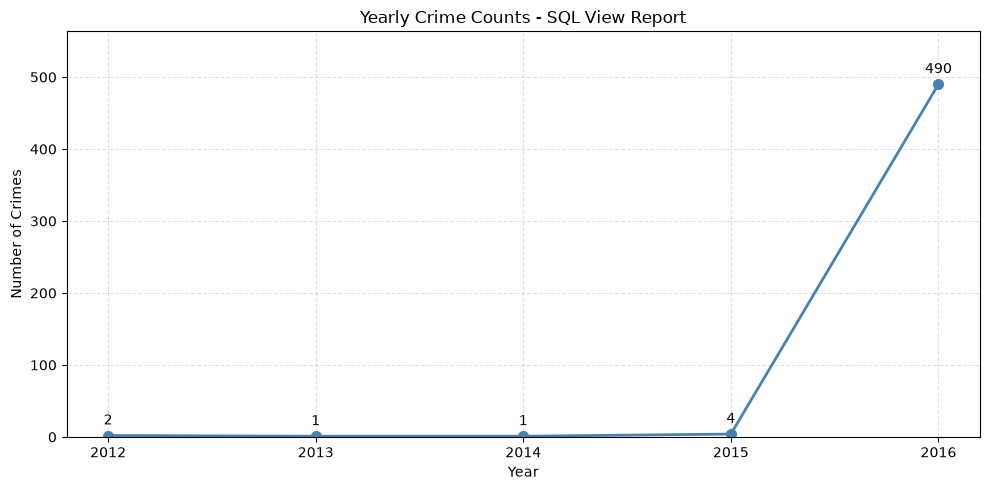

========== MATPLOTLIB CHART ==========
Chart Saved: sql_yearly_crime_report.png


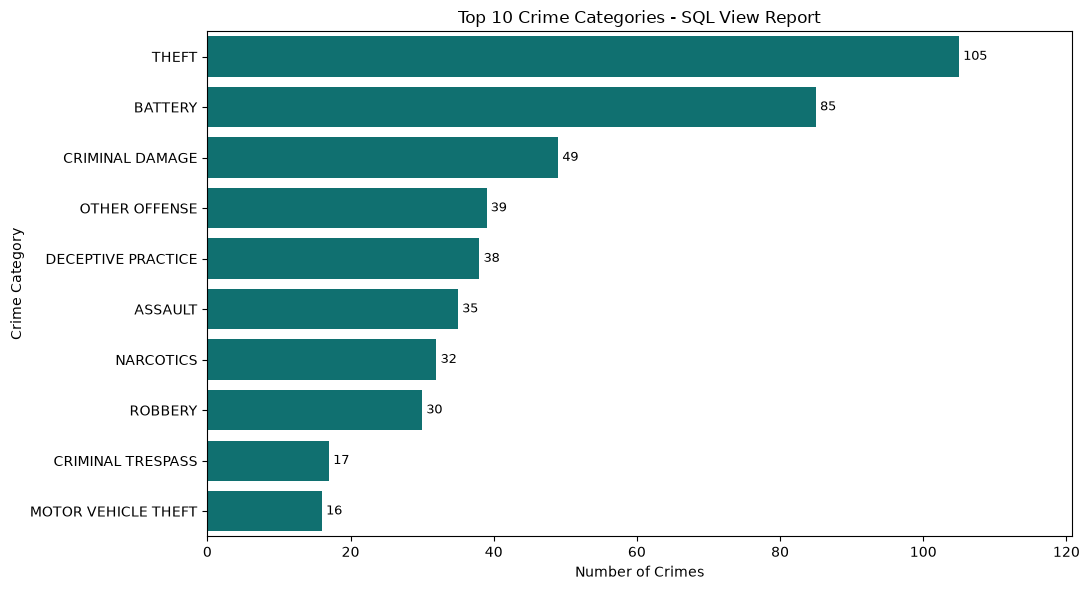


========== SEABORN CHART ==========
Chart Saved: sql_crime_category_report.png

========== SQL REPORTING INSIGHTS ==========
Year With Highest Crime Count: 2016
Highest Year Crime Count: 490
Most Frequent Crime Category: THEFT
Category Crime Count: 105
Category Percentage: 21.08%

Interpretation: The charts summarize the 498 crime records stored in the SQLite database.
The dataset is a limited sample, so its yearly counts should not be interpreted as complete Chicago crime trends.

========== USE CASE 4 SUMMARY ==========
Task 1: Design and Populate Database Tables
Task 2: Execute SQL Reporting Queries
Task 3: Create SQL Reporting Views
Task 4: Read SQL Views into Pandas
Task 5: Visualize SQL Reporting Results

Matplotlib Chart: sql_yearly_crime_report.png
Seaborn Chart: sql_crime_category_report.png

USE CASE 4 - TASK 5: PASS
USE CASE 4: ANALYSIS COMPLETE


In [10]:

# ============================================================
# USE CASE 4 - CODE CELL 5
# TASK 5: VISUALIZE SQL REPORTING RESULTS
# ============================================================

# Assessment Requirement:
# Visualize SQL reporting results using Matplotlib
# and Seaborn.
#
# Required Visualizations:
# 1. Yearly crime counts using Matplotlib.
# 2. Crime category distribution using Seaborn.
#
# Methods Used:
# plt.plot() creates the yearly crime line chart.
# sns.barplot() creates the crime category bar chart.
# sort_values() orders the reporting data.
# head(10) selects the most frequent crime categories
# for a readable visualization.
# savefig() saves charts for the Flask dashboard.


# ============================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# STEP 2: VERIFY THE SQL VIEW DATAFRAMES
# ============================================================

# These DataFrames were created in Code Cell 4.
assert "yearly_crime_df" in globals(), (
    "Run Notebook 04 - Code Cell 4 first."
)

assert "crime_category_df" in globals(), (
    "Run Notebook 04 - Code Cell 4 first."
)

# Verify that both DataFrames contain the required fields.
assert {
    "year",
    "crime_count"
}.issubset(yearly_crime_df.columns)

assert {
    "primary_type",
    "crime_count",
    "percentage"
}.issubset(crime_category_df.columns)

# Verify both SQL views represent all 498 crime records.
assert yearly_crime_df["crime_count"].sum() == 498

assert crime_category_df["crime_count"].sum() == 498


# ============================================================
# STEP 3: LOCATE THE CHART OUTPUT FOLDER
# ============================================================

BASE_DIR = Path.cwd().resolve()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

assert BASE_DIR.name == "Chicago_Crime_Capstone_2026"

CHARTS_DIR = BASE_DIR / "static" / "charts"

CHARTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# STEP 4: PREPARE YEARLY CRIME REPORTING DATA
# ============================================================

# Sort crime counts by year for chronological plotting.
yearly_plot_df = (
    yearly_crime_df
    .sort_values("year")
    .copy()
)

# Convert year and crime count to numeric values.
yearly_plot_df["year"] = pd.to_numeric(
    yearly_plot_df["year"],
    errors="raise"
).astype(int)

yearly_plot_df["crime_count"] = pd.to_numeric(
    yearly_plot_df["crime_count"],
    errors="raise"
).astype(int)


# ============================================================
# STEP 5: CREATE MATPLOTLIB YEARLY CRIME LINE CHART
# ============================================================

fig1, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(
    yearly_plot_df["year"],
    yearly_plot_df["crime_count"],
    marker="o",
    linewidth=2,
    markersize=7,
    color="steelblue"
)

ax1.set_title(
    "Yearly Crime Counts - SQL View Report"
)

ax1.set_xlabel("Year")
ax1.set_ylabel("Number of Crimes")

# Display only the years available in the dataset.
ax1.set_xticks(
    yearly_plot_df["year"]
)

ax1.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Display crime counts above each point.
for year, count in zip(
    yearly_plot_df["year"],
    yearly_plot_df["crime_count"]
):

    ax1.annotate(
        str(count),
        (year, count),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

ax1.set_ylim(
    bottom=0,
    top=yearly_plot_df["crime_count"].max() * 1.15
)

plt.tight_layout()


# ============================================================
# STEP 6: SAVE AND DISPLAY MATPLOTLIB CHART
# ============================================================

yearly_chart_path = (
    CHARTS_DIR / "sql_yearly_crime_report.png"
)

fig1.savefig(
    yearly_chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig1)

print("========== MATPLOTLIB CHART ==========")
print("Chart Saved:", yearly_chart_path.name)


# ============================================================
# STEP 7: PREPARE CRIME CATEGORY REPORTING DATA
# ============================================================

# The SQL view contains all 23 crime categories.
# Select the top 10 to make the bar chart readable.
#
# All 23 categories remain in crime_category_df.
# Only the visualization is limited to 10 categories.

top_10_sql_categories = (
    crime_category_df
    .sort_values(
        ["crime_count", "primary_type"],
        ascending=[False, True]
    )
    .head(10)
    .copy()
)

# Ensure crime counts are numeric.
top_10_sql_categories["crime_count"] = pd.to_numeric(
    top_10_sql_categories["crime_count"],
    errors="raise"
).astype(int)


# ============================================================
# STEP 8: CREATE SEABORN CRIME CATEGORY BAR CHART
# ============================================================

fig2, ax2 = plt.subplots(figsize=(11, 6))

# Horizontal bars keep category names readable.
sns.barplot(
    data=top_10_sql_categories,
    x="crime_count",
    y="primary_type",
    order=top_10_sql_categories["primary_type"],
    color="teal",
    ax=ax2
)

ax2.set_title(
    "Top 10 Crime Categories - SQL View Report"
)

ax2.set_xlabel("Number of Crimes")
ax2.set_ylabel("Crime Category")

# Display the crime count beside each bar.
for container in ax2.containers:

    ax2.bar_label(
        container,
        padding=3,
        fontsize=9
    )

ax2.set_xlim(
    0,
    top_10_sql_categories["crime_count"].max() * 1.15
)

plt.tight_layout()


# ============================================================
# STEP 9: SAVE AND DISPLAY SEABORN CHART
# ============================================================

category_chart_path = (
    CHARTS_DIR / "sql_crime_category_report.png"
)

fig2.savefig(
    category_chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig2)

print("\n========== SEABORN CHART ==========")
print("Chart Saved:", category_chart_path.name)


# ============================================================
# STEP 10: DISPLAY SQL REPORTING INSIGHTS
# ============================================================

# Identify the year with the highest crime count.
highest_year_row = yearly_plot_df.loc[
    yearly_plot_df["crime_count"].idxmax()
]

# Identify the most frequent crime category.
highest_category_row = top_10_sql_categories.iloc[0]

print("\n========== SQL REPORTING INSIGHTS ==========")

print(
    "Year With Highest Crime Count:",
    int(highest_year_row["year"])
)

print(
    "Highest Year Crime Count:",
    int(highest_year_row["crime_count"])
)

print(
    "Most Frequent Crime Category:",
    highest_category_row["primary_type"]
)

print(
    "Category Crime Count:",
    int(highest_category_row["crime_count"])
)

print(
    "Category Percentage:",
    f"{highest_category_row['percentage']:.2f}%"
)

print(
    "\nInterpretation: The charts summarize the "
    "498 crime records stored in the SQLite database."
)

print(
    "The dataset is a limited sample, so its yearly "
    "counts should not be interpreted as complete "
    "Chicago crime trends."
)


# ============================================================
# STEP 11: VALIDATE THE CHARTS AND RESULTS
# ============================================================

# Verify all yearly crime records are represented.
assert yearly_plot_df["crime_count"].sum() == 498

# Confirm the category chart shows 10 crime types.
assert len(top_10_sql_categories) == 10

# Confirm the highest-crime year.
assert int(highest_year_row["year"]) == 2016
assert int(highest_year_row["crime_count"]) == 490

# Confirm the most frequent crime category.
assert highest_category_row["primary_type"] == "THEFT"

assert int(
    highest_category_row["crime_count"]
) == 105

# Verify both charts were saved successfully.
assert yearly_chart_path.is_file()
assert yearly_chart_path.stat().st_size > 0

assert category_chart_path.is_file()
assert category_chart_path.stat().st_size > 0


# ============================================================
# STEP 12: FINAL COMPLETION STATUS
# ============================================================

print("\n========== USE CASE 4 SUMMARY ==========")

print("Task 1: Design and Populate Database Tables")
print("Task 2: Execute SQL Reporting Queries")
print("Task 3: Create SQL Reporting Views")
print("Task 4: Read SQL Views into Pandas")
print("Task 5: Visualize SQL Reporting Results")

print("\nMatplotlib Chart:", yearly_chart_path.name)
print("Seaborn Chart:", category_chart_path.name)

print("\nUSE CASE 4 - TASK 5: PASS")
print("USE CASE 4: ANALYSIS COMPLETE")
